In [7]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [8]:
# 1.데이터 불러오기
digit=datasets.load_digits()

#2. 입력/정답 분리 및 정규화
n_samples=len(digit.images)
X=digit.images.reshape(n_samples,-1)/16.0

y=digit.target.astype(np.float32)

#3. 학습/테스트 데이터 분리
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

#4. 회귀 딥러닝 모델 생성
model=tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(64,))) # 8x8 image=64 pixel 특성
model.add(tf.keras.layers.Dense(64,activation='relu'))
model.add(tf.keras.layers.Dense(32,activation='relu'))
model.add(tf.keras.layers.Dense(1)) #노드  1개, 활성화 함수 없음



In [9]:
#5. 모델 설정
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [10]:
#6. 모델 학습
history=model.fit(
    X_train, y_train,
    epochs=60,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

In [11]:
#7. 테스트 데이터 예측 및 성능 평가
y_pred=model.predict(X_test).flatten()

mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2*100:.2f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  
MSE: 0.5474
MAE: 0.4894
R2: 92.91


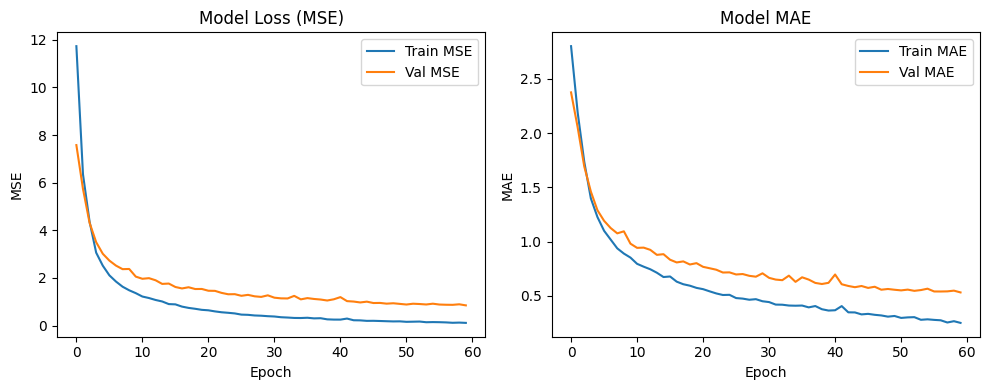

In [13]:
plt.figure(figsize=(10, 4))

# Loss (MSE) 그래프
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train MSE')
plt.plot(history.history['val_loss'], label='Val MSE')
plt.title('Model Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

# MAE 그래프
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()